In [4]:
# Cell 1: Setup
!pip install -q transformers datasets pandas matplotlib seaborn scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import pipeline
from datasets import load_dataset

sns.set_theme(style="whitegrid")
print("Environment ready!")

Environment ready!


In [5]:
# Cell 2: Data Pipeline
print("Loading validation dataset...")
dataset = load_dataset("stanfordnlp/sst2", split="validation[:500]")
df = pd.DataFrame(dataset)

# Supplement with synthetic negation/contrast sentences
synthetic_data = [
    {"sentence": "It was not good at all.", "label": 0},
    {"sentence": "The movie wasn't terrible, but it wasn't great either.", "label": 0},
    {"sentence": "I wouldn't say I disliked it.", "label": 1},
    {"sentence": "Not a single redeeming quality.", "label": 0},
    {"sentence": "It is not bad, actually quite lovely.", "label": 1},
    {"sentence": "The plot was brilliant, however the acting ruined it.", "label": 0},
    {"sentence": "Never have I ever seen such a waste of time.", "label": 0},
    {"sentence": "It's not that I hate it, but it lacks substance.", "label": 0},
    {"sentence": "Although it started slow, it turned out amazing.", "label": 1}
]
df = pd.concat([df, pd.DataFrame(synthetic_data)], ignore_index=True)

# Define linguistic feature detection
negation_words = ["not", "n't", "never", "no", "nothing", "hardly", "scarcely", "seldom"]
contrast_words = ["but", "however", "although", "yet", "despite", "nevertheless"]

def has_feature(text, word_list):
    text_lower = text.lower()
    return any(word in text_lower.split() or f"'{word}" in text_lower for word in word_list)

df['has_negation'] = df['sentence'].apply(lambda x: has_feature(x, negation_words))
df['has_contrast'] = df['sentence'].apply(lambda x: has_feature(x, contrast_words))

def categorize_row(row):
    if row['has_negation'] and row['has_contrast']:
        return 'Negation + Contrast'
    elif row['has_negation']:
        return 'Negation Only'
    elif row['has_contrast']:
        return 'Contrast Only'
    else:
        return 'Standard (Clean)'

df['category'] = df.apply(categorize_row, axis=1)
print(f"Data ready! Total rows: {len(df)}")

Loading SST-2 validation dataset...
Data ready! Total rows: 509


In [6]:
# Cell 3: Model Inference
print("Loading DistilBERT ...")
sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model="distilbert/distilbert-base-uncased-finetuned-sst-2-english",
    return_all_scores=True
)

print("Running model across dataset...")
results = sentiment_pipeline(df['sentence'].tolist())

preds, confidences = [], []
for res in results:
    if isinstance(res, list):
        pos_score = next(item['score'] for item in res if item['label'] in ['POSITIVE', 'LABEL_1'])
        neg_score = next(item['score'] for item in res if item['label'] in ['NEGATIVE', 'LABEL_0'])
        pred_label = 1 if pos_score > neg_score else 0
        confidence = max(pos_score, neg_score)
    else:
        label = res['label']
        confidence = res['score']
        pred_label = 1 if label in ['POSITIVE', 'LABEL_1'] else 0

    preds.append(pred_label)
    confidences.append(confidence)

df['predicted_label'] = preds
df['confidence'] = confidences
df['is_correct'] = (df['label'] == df['predicted_label'])

print("Inference completed successfully!")

Loading DistilBERT model...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Running model inference across dataset...
Inference completed successfully!


--- SUMMARY METRICS BY CATEGORY ---
              category  is_correct  count      mean
0        Contrast Only       False      4  0.846392
1        Contrast Only        True     43  0.989497
2  Negation + Contrast       False      4  0.980936
3  Negation + Contrast        True     26  0.992509
4        Negation Only       False      8  0.912827
5        Negation Only        True     67  0.982030
6     Standard (Clean)       False     28  0.952863
7     Standard (Clean)        True    329  0.989930


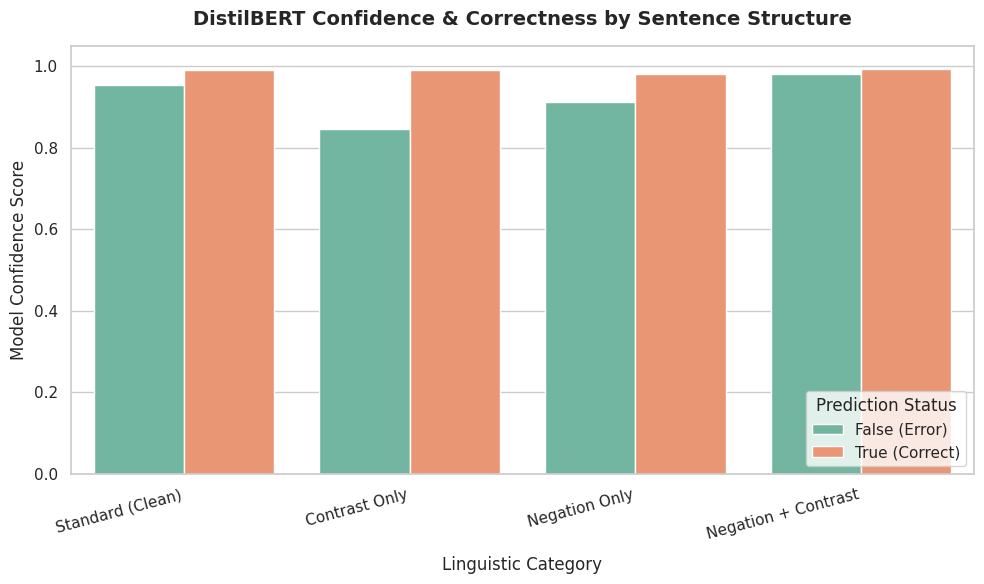

In [7]:
# Cell 4: Plotting & Metrics
print("--- SUMMARY METRICS BY CATEGORY ---")
metrics = df.groupby(['category', 'is_correct'])['confidence'].agg(['count', 'mean']).reset_index()
print(metrics)

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=df,
    x='category',
    y='confidence',
    hue='is_correct',
    palette='Set2',
    errorbar=None
)

plt.title("DistilBERT Confidence & Correctness by Sentence Structure", fontsize=14, weight='bold', pad=15)
plt.xlabel("Linguistic Category", fontsize=12, labelpad=10)
plt.ylabel("Model Confidence Score", fontsize=12)
plt.legend(title="Prediction Status", labels=['False (Error)', 'True (Correct)'], loc='lower right')
plt.ylim(0, 1.05)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()

plt.savefig("phase_1_ai_confidence_plot_fixed.png", dpi=300, bbox_inches='tight')
plt.show()